In [16]:

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Project paths
ROOT = Path.cwd().parent
PROCESSED = ROOT / "data" / "processed"
SRC = ROOT / "src"

# Import project functions
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from features import extract_possession_statistics

# Load predictions
raw_codes = np.load(PROCESSED / "raw_codes.npy")

predictions = {
    window: np.load(
        PROCESSED / f"predictions_smooth_{window}.npy"
    )
    for window in [25, 50, 125]
}

# Verify data
print("Raw codes:", len(raw_codes))

for window, labels in predictions.items():
    print(
        f"Window {window}:",
        len(labels),
        "| Labels:",
        np.unique(labels)
    )

assert len(raw_codes) == 199319

for labels in predictions.values():
    assert len(labels) == 199319


Raw codes: 199319
Window 25: 199319 | Labels: ['A' 'D' 'H']
Window 50: 199319 | Labels: ['A' 'D' 'H']
Window 125: 199319 | Labels: ['A' 'D' 'H']


In [17]:

comparison = []

for window, labels in predictions.items():

    stats = extract_possession_statistics(labels)

    comparison.append({
        "window": window,
        "home_frames": int((labels == "H").sum()),
        "away_frames": int((labels == "A").sum()),
        "dead_frames": int((labels == "D").sum()),
        "possession_count": len(stats),
        "mean_duration_seconds": (
            round(stats["duration_seconds"].mean(), 2)
            if len(stats) > 0 else 0
        ),
        "median_duration_seconds": (
            round(stats["duration_seconds"].median(), 2)
            if len(stats) > 0 else 0
        )
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df)



,window,home_frames,away_frames,dead_frames,possession_count,mean_duration_seconds,median_duration_seconds
0,25,69446,51303,78570,851,5.68,3.12
1,50,72957,54842,71520,669,7.64,4.72
2,125,82758,62124,54437,430,13.48,8.58


In [13]:
for window, labels in predictions.items():

    changes = np.sum(labels[1:] != labels[:-1])

    print(
        "Window:", window,
        "| Label transitions:", int(changes)
    )

Window: 25 | Label transitions: 992
Window: 50 | Label transitions: 810
Window: 125 | Label transitions: 515


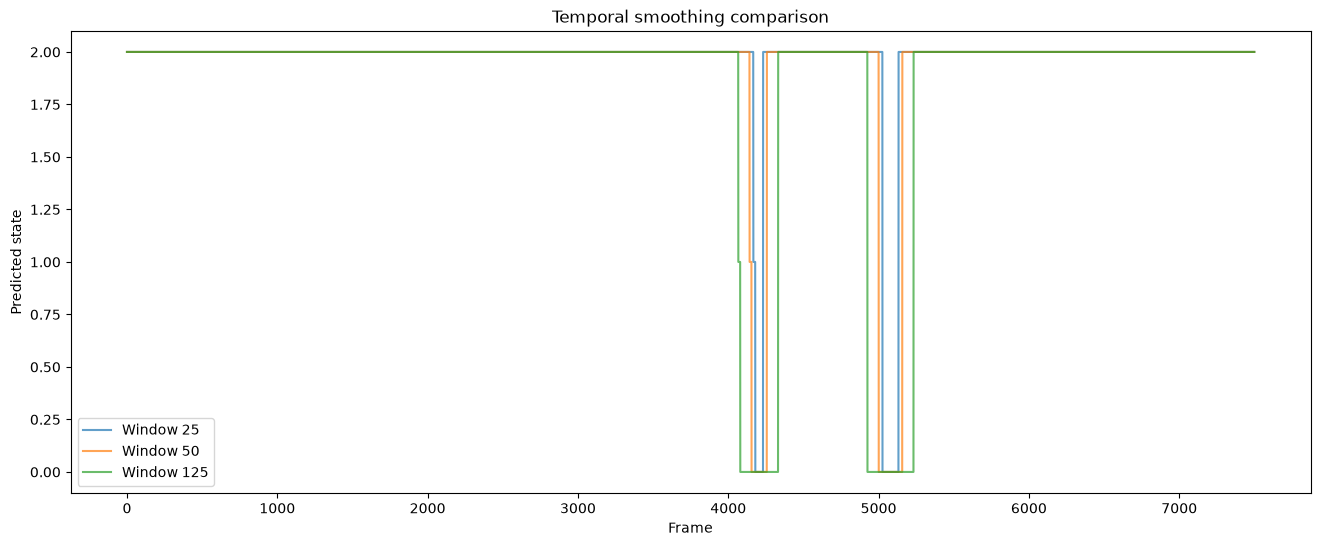

In [14]:
plt.figure(figsize=(16, 6))

for window, labels in predictions.items():

    values = np.where(
        labels == "H", 0,
        np.where(labels == "A", 1, 2)
    )

    plt.plot(
        values[:7500],
        label=f"Window {window}",
        alpha=0.7
    )

plt.title("Temporal smoothing comparison")
plt.xlabel("Frame")
plt.ylabel("Predicted state")
plt.legend()
plt.show()

In [15]:
# The published full-match reference baseline uses +/- 50 frames.
# We do not choose parameters using the public 5-minute ground truth.

FINAL_WINDOW = 50

final_labels = predictions[FINAL_WINDOW]

print("Selected reference window:", FINAL_WINDOW)
print("Total frames:", len(final_labels))

print(
    pd.Series(final_labels).value_counts()
)

assert len(final_labels) == 199319

Selected reference window: 50
Total frames: 199319
H    72957
D    71520
A    54842
Name: count, dtype: int64
